# #Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following tasks:
1.	Pre-process the dataset.
2.	Identify outliers.
3.	Check the correlation.
4.	Implement linear regression and random forest regression models.
5.	Evaluate the models and compare their respective scores like R2, RMSE, etc. Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset


In [1]:
#Importing the required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#importing the dataset
df  = pd.read_csv("/content/uber.csv")

##  1.	Pre-process the dataset.

In [3]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1.0
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1.0
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1.0
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3.0
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5.0


In [4]:
df.info() #To get the required information of the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26782 entries, 0 to 26781
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         26782 non-null  int64  
 1   key                26782 non-null  object 
 2   fare_amount        26782 non-null  float64
 3   pickup_datetime    26782 non-null  object 
 4   pickup_longitude   26782 non-null  float64
 5   pickup_latitude    26782 non-null  float64
 6   dropoff_longitude  26782 non-null  float64
 7   dropoff_latitude   26782 non-null  float64
 8   passenger_count    26781 non-null  float64
dtypes: float64(6), int64(1), object(2)
memory usage: 1.8+ MB


In [5]:
df.columns #TO get number of columns in the dataset

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

In [6]:
df = df.drop(['Unnamed: 0', 'key'], axis= 1) #To drop unnamed column as it isn't required

In [7]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1.0
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1.0
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1.0
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3.0
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5.0


In [8]:
df.shape #To get the total (Rows,Columns)

(26782, 7)

In [9]:
df.dtypes #To get the type of each column

fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count      float64
dtype: object

In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26782 entries, 0 to 26781
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fare_amount        26782 non-null  float64
 1   pickup_datetime    26782 non-null  object 
 2   pickup_longitude   26782 non-null  float64
 3   pickup_latitude    26782 non-null  float64
 4   dropoff_longitude  26782 non-null  float64
 5   dropoff_latitude   26782 non-null  float64
 6   passenger_count    26781 non-null  float64
dtypes: float64(6), object(1)
memory usage: 1.4+ MB


In [11]:
df.describe() #To get statistics of each columns

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,26782.000000,26782.000000,26782.000000,26782.000000,26782.000000,26781.000000
mean,11.408959,-72.562221,39.940947,-72.552649,39.942696,1.674695
std,10.134094,11.126212,6.065942,10.274646,6.060997,1.294758
min,0.000000,-748.016667,-74.015515,-75.350437,-74.008745,0.000000
25%,6.000000,-73.992071,40.734930,-73.991518,40.733806,1.000000
50%,8.500000,-73.981849,40.752453,-73.980202,40.752927,1.000000
75%,12.900000,-73.967331,40.767125,-73.963433,40.768172,2.000000
max,350.000000,40.770667,45.031653,40.828377,45.031598,6.000000


### Filling Missing values

In [ ]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [ ]:
df['dropoff_latitude'].fillna(value=df['dropoff_latitude'].mean(),inplace = True)
df['dropoff_longitude'].fillna(value=df['dropoff_longitude'].median(),inplace = True)

In [12]:
df['dropoff_latitude']

0        40.723217
1        40.750325
2        40.772647
3        40.803349
4        40.761247
           ...    
26777    40.666842
26778    40.738749
26779    40.743873
26780    40.704136
26781    40.766331
Name: dropoff_latitude, Length: 26782, dtype: float64

In [13]:
df.head(10)

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1.0
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1.0
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1.0
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3.0
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5.0
5,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1.0
6,24.5,2014-10-12 07:04:00 UTC,-73.961447,40.693965,-73.871195,40.774297,5.0
7,2.5,2012-12-11 13:52:00 UTC,0.000000,0.000000,0.000000,0.000000,1.0
8,9.7,2012-02-17 09:32:00 UTC,-73.975187,40.745767,-74.002720,40.743537,1.0
9,12.5,2012-03-29 19:06:00 UTC,-74.001065,40.741787,-73.963040,40.775012,1.0


In [14]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      1
dtype: int64

In [15]:
df.dtypes

fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count      float64
dtype: object

### Column pickup_datetime is in wrong format (Object). Convert it to DateTime Format

In [19]:
df.pickup_datetime = pd.to_datetime(df.pickup_datetime,)

In [20]:
df.dtypes

fare_amount                      float64
pickup_datetime      datetime64[ns, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                  float64
dtype: object

### To segregate each time of date and time

In [21]:
df= df.assign(hour = df.pickup_datetime.dt.hour,
             day= df.pickup_datetime.dt.day,
             month = df.pickup_datetime.dt.month,
             year = df.pickup_datetime.dt.year,
             dayofweek = df.pickup_datetime.dt.dayofweek)

In [22]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1.0,19,7,5,2015,3
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1.0,20,17,7,2009,4
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1.0,21,24,8,2009,0
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3.0,8,26,6,2009,4
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5.0,17,28,8,2014,3


In [23]:
# drop the column 'pickup_daetime' using drop()
# 'axis = 1' drops the specified column

df = df.drop('pickup_datetime',axis=1)


In [24]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1.0,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1.0,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1.0,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5.0,17,28,8,2014,3


In [25]:
df.dtypes

fare_amount          float64
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count      float64
hour                   int32
day                    int32
month                  int32
year                   int32
dayofweek              int32
dtype: object

## Checking outliers and filling them

fare_amount             Axes(0.125,0.786098;0.352273x0.0939024)
pickup_longitude     Axes(0.547727,0.786098;0.352273x0.0939024)
pickup_latitude         Axes(0.125,0.673415;0.352273x0.0939024)
dropoff_longitude    Axes(0.547727,0.673415;0.352273x0.0939024)
dropoff_latitude        Axes(0.125,0.560732;0.352273x0.0939024)
passenger_count      Axes(0.547727,0.560732;0.352273x0.0939024)
hour                    Axes(0.125,0.448049;0.352273x0.0939024)
day                  Axes(0.547727,0.448049;0.352273x0.0939024)
month                   Axes(0.125,0.335366;0.352273x0.0939024)
year                 Axes(0.547727,0.335366;0.352273x0.0939024)
dayofweek               Axes(0.125,0.222683;0.352273x0.0939024)
dtype: object

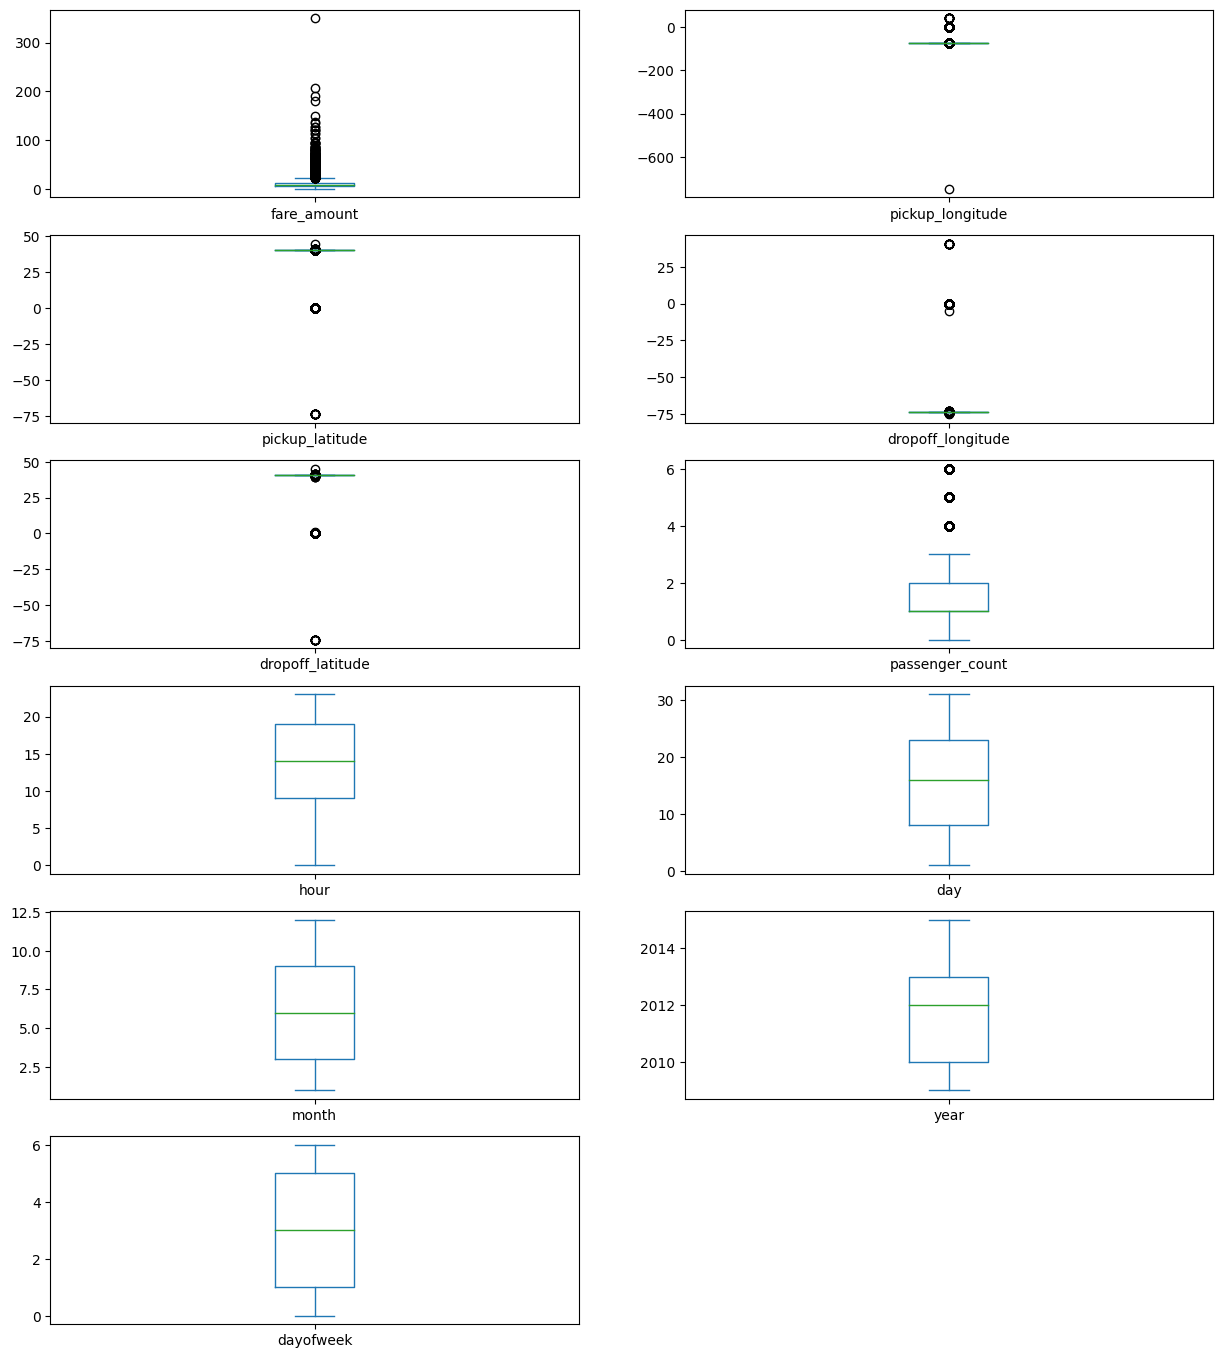

In [26]:
df.plot(kind = "box",subplots = True,layout = (7,2),figsize=(15,20)) #Boxplot to check the outliers

In [27]:
#Using the InterQuartile Range to fill the values
def remove_outlier(df1 , col):
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_whisker = Q1-1.5*IQR
    upper_whisker = Q3+1.5*IQR
    df[col] = np.clip(df1[col] , lower_whisker , upper_whisker)
    return df1

def treat_outliers_all(df1 , col_list):
    for c in col_list:
        df1 = remove_outlier(df , c)
    return df1

In [28]:
df = treat_outliers_all(df , df.iloc[: , 0::])

fare_amount             Axes(0.125,0.786098;0.352273x0.0939024)
pickup_longitude     Axes(0.547727,0.786098;0.352273x0.0939024)
pickup_latitude         Axes(0.125,0.673415;0.352273x0.0939024)
dropoff_longitude    Axes(0.547727,0.673415;0.352273x0.0939024)
dropoff_latitude        Axes(0.125,0.560732;0.352273x0.0939024)
passenger_count      Axes(0.547727,0.560732;0.352273x0.0939024)
hour                    Axes(0.125,0.448049;0.352273x0.0939024)
day                  Axes(0.547727,0.448049;0.352273x0.0939024)
month                   Axes(0.125,0.335366;0.352273x0.0939024)
year                 Axes(0.547727,0.335366;0.352273x0.0939024)
dayofweek               Axes(0.125,0.222683;0.352273x0.0939024)
dtype: object

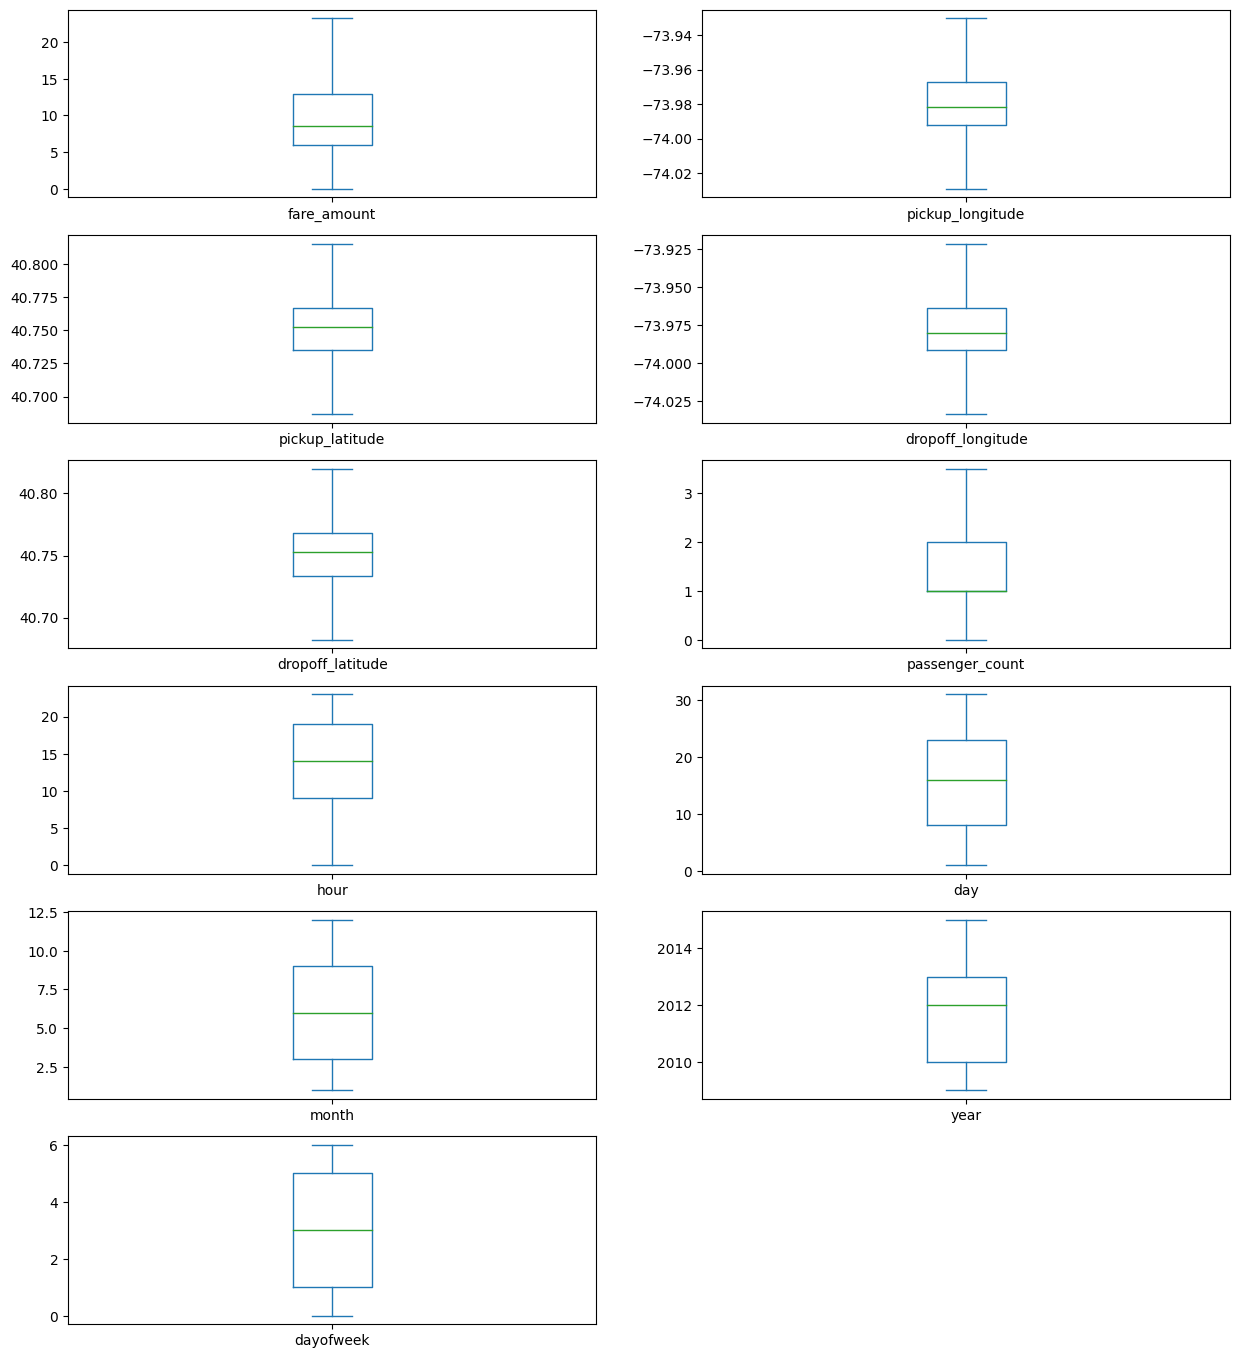

In [29]:
df.plot(kind = "box",subplots = True,layout = (7,2),figsize=(15,20)) #Boxplot shows that dataset is free from outliers

In [ ]:
#!pip install haversine

In [30]:
!pip install haversine
import haversine as hs  #Calculate the distance using Haversine to calculate the distance between to points. Can't use Eucladian as it is for flat surface.
travel_dist = []
for pos in range(len(df['pickup_longitude'])):
        long1,lati1,long2,lati2 = [df['pickup_longitude'][pos],df['pickup_latitude'][pos],df['dropoff_longitude'][pos],df['dropoff_latitude'][pos]]
        loc1=(lati1,long1)
        loc2=(lati2,long2)
        c = hs.haversine(loc1,loc2)
        travel_dist.append(c)

print(travel_dist)
df['dist_travel_km'] = travel_dist
df.head()

[1.6833250775073447, 2.4575932783467835, 5.036384146783453, 1.661685753650294, 4.08365783877083, 0.0, 9.551360824714857, 0.895660701005102, 2.3327142314177545, 4.889423641655177, 2.2508607308770285, 0.895660701005102, 0.3022521108558365, 3.5812557740132496, 1.3099517093917648, 1.716279792276335, 0.7299665570466272, 2.515953547298386, 1.790321726187665, 1.0347050399795192, 2.4902472008677727, 0.9594701844599927, 1.2613897673437817, 1.7517650017211177, 6.1932445014761095, 2.736192584061414, 0.7232537124105735, 3.229443537425455, 1.4295172964395384, 2.233699311547041, 11.051817662233455, 1.8950491608266506, 1.9049353402365328, 3.1821178242889583, 4.440673830461235, 2.9230236888626995, 1.200213842045202, 2.635790807404098, 2.253613903554444, 9.226811195105677, 4.826533532872274, 1.2502926870845612, 0.7984742276755328, 0.840396152683202, 0.38519924001701444, 2.434346176233359, 3.127909533264099, 3.7346507724526368, 0.0, 4.504360509008704, 1.5579008497303448, 4.923160610490316, 7.68315806816

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1.0,19,7,5,2015,3,1.683325
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1.0,20,17,7,2009,4,2.457593
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1.0,21,24,8,2009,0,5.036384
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,26,6,2009,4,1.661686
4,16.0,-73.930221,40.744085,-73.973082,40.761247,3.5,17,28,8,2014,3,4.083658


In [ ]:
travel_dist

[1.6833250775073447,
 2.4575932783467835,
 5.036384146783453,
 1.661685753650294,
 4.1160881895779955,
 0.0,
 9.529776771411873,
 0.7719995370784762,
 2.3327142314177545,
 4.889423641655177,
 2.2508607308770285,
 0.7719995370784762,
 0.3022521108558365,
 3.5812557740132496,
 1.3099517093917648,
 1.716279792276335,
 0.7299665570466272,
 2.515953547298386,
 1.790321726187665,
 1.0347050399795192,
 2.4902472008677727,
 0.9594701844599927,
 1.2613897673437817,
 1.7517650017211177,
 6.1932445014761095,
 2.736192584061414,
 0.7232537124105735,
 3.229443537425455,
 1.4295172964395384,
 2.233699311547041,
 11.081439278313375,
 1.8950491608266506,
 1.9049353402365328,
 3.1821178242889583,
 4.467427177611096,
 2.9230236888626995,
 1.200213842045202,
 2.635790807404098,
 2.253613903554444,
 9.186987668633932,
 4.826533532872274,
 1.2502926870845612,
 0.7984742276755328,
 0.840396152683202,
 0.38519924001701444,
 2.434346176233359,
 3.127909533264099,
 3.7346507724526368,
 0.0,
 4.504360509008704,

In [ ]:
#Uber doesn't travel over 130 kms so minimize the distance
df= df.loc[(df.dist_travel_km >= 1) | (df.dist_travel_km <= 130)]
print("Remaining observastions in the dataset:", df.shape)

Remaining observastions in the dataset: (200000, 12)


In [ ]:
#Finding inccorect latitude (Less than or greater than 90) and longitude (greater than or less than 180)
incorrect_coordinates = df.loc[(df.pickup_latitude > 90) |(df.pickup_latitude < -90) |
                                   (df.dropoff_latitude > 90) |(df.dropoff_latitude < -90) |
                                   (df.pickup_longitude > 180) |(df.pickup_longitude < -180) |
                                   (df.dropoff_longitude > 180) |(df.dropoff_longitude < -180)
                                    ]

In [ ]:
incorrect_coordinates

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km


In [ ]:
df.drop(incorrect_coordinates, inplace = True, errors = 'ignore')

In [ ]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1.0,19,7,5,2015,3,1.683325
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1.0,20,17,7,2009,4,2.457593
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1.0,21,24,8,2009,0,5.036384
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,26,6,2009,4,1.661686
4,16.0,-73.929786,40.744085,-73.973082,40.761247,3.5,17,28,8,2014,3,4.116088


In [ ]:
df.isnull().sum()

fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
year                 0
dayofweek            0
dist_travel_km       0
dtype: int64

<Axes: >

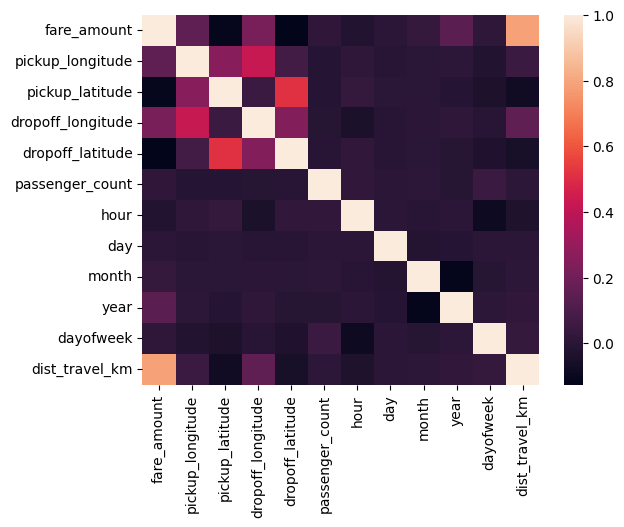

In [ ]:
sns.heatmap(df.corr()) #Free for null values

In [ ]:
corr = df.corr() #Function to find the correlation

In [ ]:
corr

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
fare_amount,1.000000,0.154069,-0.110842,0.218675,-0.125898,0.015778,-0.023623,0.004534,0.030817,0.141277,0.013652,0.786385
pickup_longitude,0.154069,1.000000,0.259497,0.425619,0.073290,-0.013213,0.011579,-0.003204,0.001169,0.010198,-0.024652,0.048446
pickup_latitude,-0.110842,0.259497,1.000000,0.048889,0.515714,-0.012889,0.029681,-0.001553,0.001562,-0.014243,-0.042310,-0.073362
dropoff_longitude,0.218675,0.425619,0.048889,1.000000,0.245667,-0.009303,-0.046558,-0.004007,0.002391,0.011346,-0.003336,0.155191
dropoff_latitude,-0.125898,0.073290,0.515714,0.245667,1.000000,-0.006308,0.019783,-0.003479,-0.001193,-0.009603,-0.031919,-0.052701
passenger_count,0.015778,-0.013213,-0.012889,-0.009303,-0.006308,1.000000,0.020274,0.002712,0.010351,-0.009749,0.048550,0.009884
hour,-0.023623,0.011579,0.029681,-0.046558,0.019783,0.020274,1.000000,0.004677,-0.003926,0.002156,-0.086947,-0.035708
day,0.004534,-0.003204,-0.001553,-0.004007,-0.003479,0.002712,0.004677,1.000000,-0.017360,-0.012170,0.005617,0.001709
month,0.030817,0.001169,0.001562,0.002391,-0.001193,0.010351,-0.003926,-0.017360,1.000000,-0.115859,-0.008786,0.010050
year,0.141277,0.010198,-0.014243,0.011346,-0.009603,-0.009749,0.002156,-0.012170,-0.115859,1.000000,0.006113,0.022294


<Axes: >

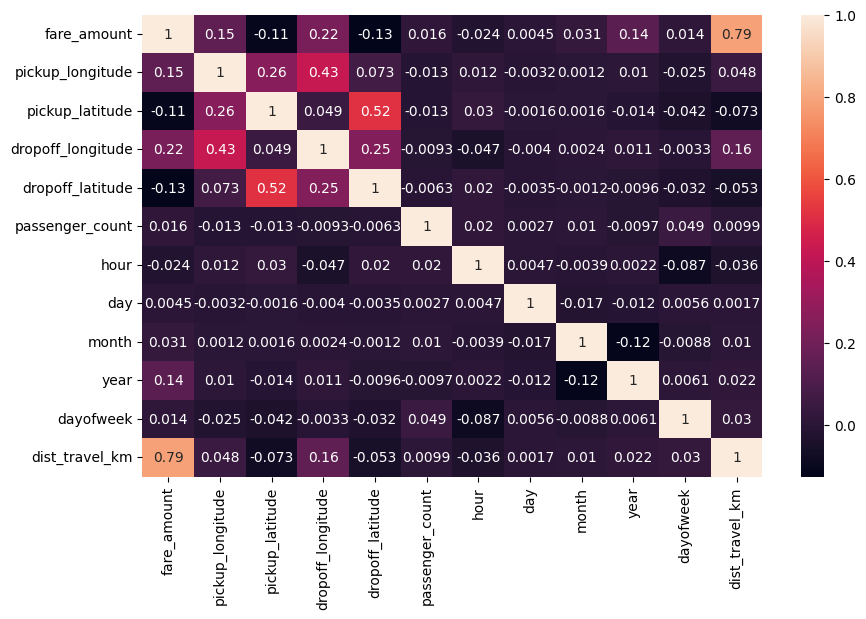

In [ ]:
fig,axis = plt.subplots(figsize = (10,6))
sns.heatmap(df.corr(),annot = True) #Correlation Heatmap (Light values means highly correlated)

### Dividing the dataset into feature and target values

In [ ]:
x = df[['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude','passenger_count','hour','day','month','year','dayofweek','dist_travel_km']]

In [ ]:
y = df['fare_amount']

### Dividing the dataset into training and testing dataset

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.20)

In [ ]:
X_train

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
198699,-73.990752,40.750577,-73.989277,40.739347,3.5,11,10,6,2013,0,1.254888
27240,-73.996038,40.725168,-73.977357,40.713760,1.0,17,20,6,2012,2,2.021817
52173,-73.971787,40.749967,-73.991157,40.732895,2.0,18,29,8,2013,3,2.503337
132967,-73.996512,40.729365,-74.013494,40.715590,1.0,14,20,5,2011,4,2.096241
54101,-73.970250,40.761146,-73.988847,40.737858,1.0,19,26,4,2012,3,3.026504
...,...,...,...,...,...,...,...,...,...,...,...
168828,-73.957367,40.773960,-73.984643,40.742642,1.0,15,4,2,2013,0,4.171941
183479,-73.994298,40.762863,-74.004957,40.766188,2.0,5,18,10,2009,6,0.970848
196400,-73.964095,40.808040,-73.951300,40.785890,1.0,19,25,6,2013,1,2.688174
178307,-73.957367,40.781902,-73.962490,40.774702,1.0,19,16,5,2013,3,0.909419


In [ ]:
X_test

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_travel_km
159333,-73.929786,40.769980,-73.983119,40.756558,1.0,10,9,4,2012,0,4.733180
146273,-73.988140,40.737652,-73.974270,40.751122,1.0,20,14,5,2011,5,1.899665
7825,-73.929786,40.774120,-73.922036,40.819268,1.0,20,19,5,2015,1,5.062447
136815,-74.009382,40.738111,-73.998983,40.760922,2.0,0,5,8,2009,2,2.683477
41756,-73.929786,40.686252,-73.922036,40.682556,1.0,12,8,6,2010,1,0.772000
...,...,...,...,...,...,...,...,...,...,...,...
34158,-74.005563,40.705633,-73.990305,40.731624,1.0,14,5,6,2011,6,3.163235
99386,-73.981587,40.758662,-73.951835,40.781830,3.0,15,28,5,2014,2,3.593609
106161,-73.973318,40.743732,-73.958763,40.763990,1.0,18,28,3,2012,2,2.564615
152210,-73.929786,40.686252,-73.922036,40.682556,3.5,2,14,1,2015,2,0.772000


In [ ]:
y_train

198699     8.5
27240      6.9
52173     13.5
132967     8.5
54101      9.7
          ... 
168828    13.5
183479     4.9
196400    10.0
178307     4.5
153907     6.9
Name: fare_amount, Length: 160000, dtype: float64

In [ ]:
y_test

159333    22.25
146273     6.90
7825      22.25
136815     8.50
41756      7.70
          ...  
34158      8.90
99386     12.00
106161     5.70
152210    10.50
823       16.50
Name: fare_amount, Length: 40000, dtype: float64

### Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()

In [ ]:
regression.fit(X_train,y_train)

LinearRegression()

In [ ]:
regression.intercept_ #To find the linear intercept

3626.4953282033243

In [ ]:
regression.coef_ #To find the linear coeeficient

array([ 2.50837122e+01, -6.82210074e+00,  2.00893981e+01, -1.83313644e+01,
        6.54741657e-02,  6.10246200e-03,  2.68690288e-03,  5.99137769e-02,
        3.70192062e-01, -3.17554087e-02,  1.84234475e+00])

In [ ]:
prediction = regression.predict(X_test) #To predict the target values

In [ ]:
print(prediction)

[14.46220211  7.88153065 16.34475509 ...  9.88359159 11.31483918
 15.41638346]


In [ ]:
y_test

159333    22.25
146273     6.90
7825      22.25
136815     8.50
41756      7.70
          ...  
34158      8.90
99386     12.00
106161     5.70
152210    10.50
823       16.50
Name: fare_amount, Length: 40000, dtype: float64

### Metrics Evaluation using R2, Mean Squared Error, Root Mean Sqared Error

In [ ]:
from sklearn.metrics import r2_score

In [ ]:
r2_score(y_test,prediction)

0.6729516131874637

In [ ]:
from sklearn.metrics import mean_squared_error

In [ ]:
MSE = mean_squared_error(y_test,prediction)

In [ ]:
MSE

9.666234862895655

In [ ]:
RMSE = np.sqrt(MSE)

In [ ]:
RMSE

3.109056908918789

### Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf = RandomForestRegressor(n_estimators=50) #Here n_estimators means number of trees you want to build before making the prediction

In [ ]:
rf.fit(X_train,y_train)

RandomForestRegressor(n_estimators=50)

In [ ]:
y_pred = rf.predict(X_test)

In [ ]:
y_pred

array([ 8.941,  6.364,  9.764, ...,  6.93 , 11.64 , 12.198])

### Metrics evaluatin for Random Forest

In [ ]:
R2_Random = r2_score(y_test,y_pred)

In [ ]:
R2_Random

0.7934089930936369

In [ ]:
MSE_Random = mean_squared_error(y_test,y_pred)

In [ ]:
MSE_Random

6.0477900228586

In [ ]:
RMSE_Random = np.sqrt(MSE_Random)

In [ ]:
RMSE_Random

2.4592254924790042